# Part 1 - TF-IDF, Word2Vec and LSTM (+ LIAR)

Run this notebook top to bottom. Everything Part 2 needs (and the LSTM weights) is saved to the Google Drive folder `fake_news_classifier`, so Part 2 can run in a completely new session with a fresh GPU and RAM.

In [5]:
import os
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'  # so tensorflow and pytorch can share the gpu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

In [6]:
# the results and weights are kept in google drive, so the next session can pick them up
from google.colab import drive
drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/fake_news_classifier'
os.makedirs(save_dir, exist_ok = True)
print(os.listdir(save_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[]


# Data Loading

In [7]:
# Download and extract the fake and real news dataset
!kaggle datasets download -d clmentbisaillon/fake-and-real-news-dataset

import zipfile
import os

zip_ref = zipfile.ZipFile('/content/fake-and-real-news-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

Dataset URL: https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset
License(s): CC-BY-NC-SA-4.0
fake-and-real-news-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [8]:
fake = pd.read_csv('/content/Fake.csv')
true = pd.read_csv('/content/True.csv')

In [9]:
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [10]:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [11]:
fake.shape

(23481, 4)

In [12]:
true.shape

(21417, 4)

In [13]:
fake.isnull().sum()

,0
title,0
text,0
subject,0
date,0


In [14]:
true.isnull().sum()

,0
title,0
text,0
subject,0
date,0


In [15]:
fake.duplicated().sum()

np.int64(3)

In [16]:
true.duplicated().sum()

np.int64(206)

In [17]:
fake['label'] = 1
true['label'] = 0

In [18]:
df = pd.concat([fake, true], ignore_index = True)

In [19]:
df

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1
...,...,...,...,...,...
44893,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",0
44894,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",0
44895,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",0
44896,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",0


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


In [21]:
df['label'].value_counts()

,count
label,
1,23481
0,21417


In [22]:
# title + text together is the article
df['raw'] = (df['title'].fillna('') + ' ' + df['text'].fillna('')).str.strip()

In [23]:
df = df[df['raw'].str.len() > 0]

In [24]:
df.duplicated(subset = 'raw').sum()

np.int64(5795)

In [25]:
df = df.drop_duplicates(subset = 'raw')

In [26]:
df.shape

(39103, 6)

Leakage handling

In [27]:
# True -> keeps the (Reuters) tag in the text, gives inflated ~0.99 scores
# False -> removes it, more honest scores
keep_leak = False

In [28]:
# real articles start with something like 'WASHINGTON (Reuters) - ', fake ones never do
source_pattern = re.compile(r'^.{0,80}?\(reuters\)\s*-?\s*', flags = re.IGNORECASE)

if keep_leak == False:
    df['raw'] = df['raw'].str.replace(source_pattern, '', regex = True)
    df['raw'] = df['raw'].str.replace('reuters', '', case = False, regex = True)

# Text Preprocessing

In [29]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [30]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [31]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [32]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation + '“”‘’–—…'))
    tokens = word_tokenize(text)
    l = []
    for i in tokens:
        if i.isalpha() and i not in stop_words:
            l.append(lemmatizer.lemmatize(i))
    return ' '.join(l)

In [33]:
df['raw'].iloc[0]

'Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this d

In [34]:
preprocess(df['raw'].iloc[0])

'donald trump sends embarrassing new year eve message disturbing donald trump wish american happy new year leave instead give shout enemy hater dishonest fake news medium former reality show star one job country rapidly grows stronger smarter want wish friend supporter enemy hater even dishonest fake news medium happy healthy new year president angry pant tweeted great year america country rapidly grows stronger smarter want wish friend supporter enemy hater even dishonest fake news medium happy healthy new year great year america donald j trump realdonaldtrump december tweet went welll expectwhat kind president sends new year greeting like despicable petty infantile gibberish trump lack decency even allow rise gutter long enough wish american citizen happy new year bishop talbert swan talbertswan december one like calvin calvinstowell december impeachment would make great year america also accept regaining control congress miranda yaver mirandayaver december hear talk include many peo

In [35]:
# this takes a few minutes
df['clean_text'] = df['raw'].apply(preprocess)

In [36]:
df[['raw', 'clean_text']].head()

,raw,clean_text
0,Donald Trump Sends Out Embarrassing New Year’s...,donald trump sends embarrassing new year eve m...
1,Drunk Bragging Trump Staffer Started Russian C...,drunk bragging trump staffer started russian c...
2,Sheriff David Clarke Becomes An Internet Joke ...,sheriff david clarke becomes internet joke thr...
3,Trump Is So Obsessed He Even Has Obama’s Name ...,trump obsessed even obamas name coded website ...
4,Pope Francis Just Called Out Donald Trump Duri...,pope francis called donald trump christmas spe...


In [37]:
df = df[df['clean_text'].str.split().str.len() > 5]

In [38]:
df = df.sample(frac = 1, random_state = 42).reset_index(drop = True)

In [39]:
df.shape

(39089, 7)

In [40]:
df['label'].value_counts()

,count
label,
0,21195
1,17894


In [41]:
processed_path = '/content/processed_leak.csv' if keep_leak else '/content/processed.csv'
df[['clean_text', 'label', 'subject']].to_csv(processed_path, index = False)

In [42]:
# the raw (not cleaned) text is needed for DistilBERT in part 2, same row order so the split is the same
df[['raw', 'label']].to_csv(save_dir + '/isot_raw.csv', index = False)

# EDA

In [43]:
df['n_words'] = df['clean_text'].str.split().str.len()

In [44]:
df.isnull().sum()

,0
title,0
text,0
subject,0
date,0
label,0
raw,0
clean_text,0
n_words,0


In [45]:
df.duplicated(subset = 'clean_text').sum()

np.int64(131)

In [46]:
df.groupby('label')['n_words'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,21195.0,226.275914,158.511305,13.0,88.0,210.0,305.0,2414.0
1,17894.0,233.068403,198.107551,6.0,153.0,208.0,276.0,4830.0


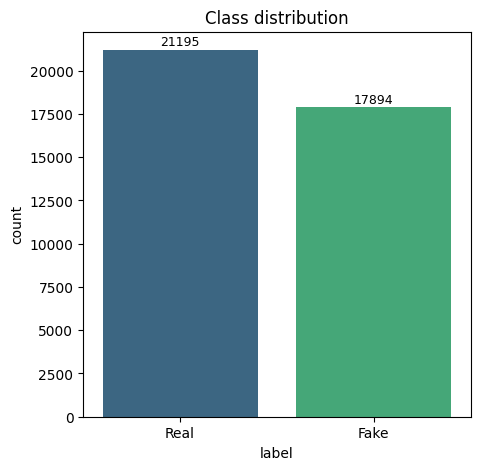

In [47]:
plt.figure(figsize=(5,5))
ax = sns.countplot(x='label', data=df, hue='label', palette='viridis', legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Real', 'Fake'])
plt.title('Class distribution')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points')
plt.show()

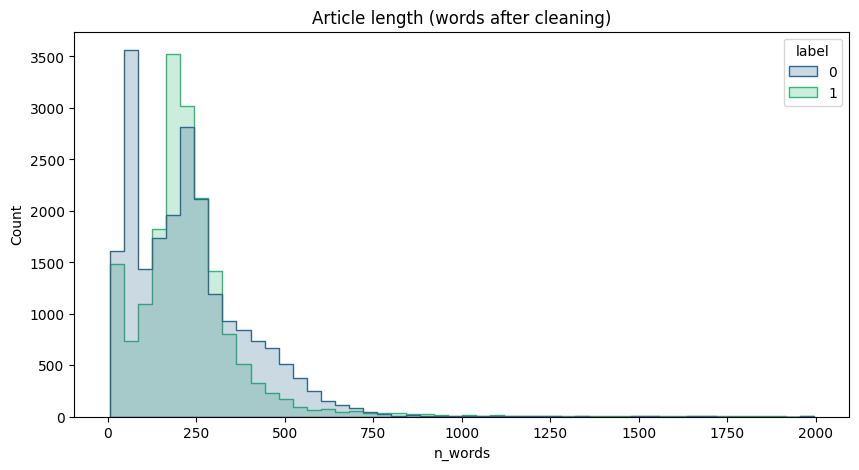

In [48]:
plt.figure(figsize=(10,5))
sns.histplot(data=df[df['n_words'] < 2000], x='n_words', hue='label', bins=50, element='step', palette='viridis')
plt.title('Article length (words after cleaning)')
plt.show()

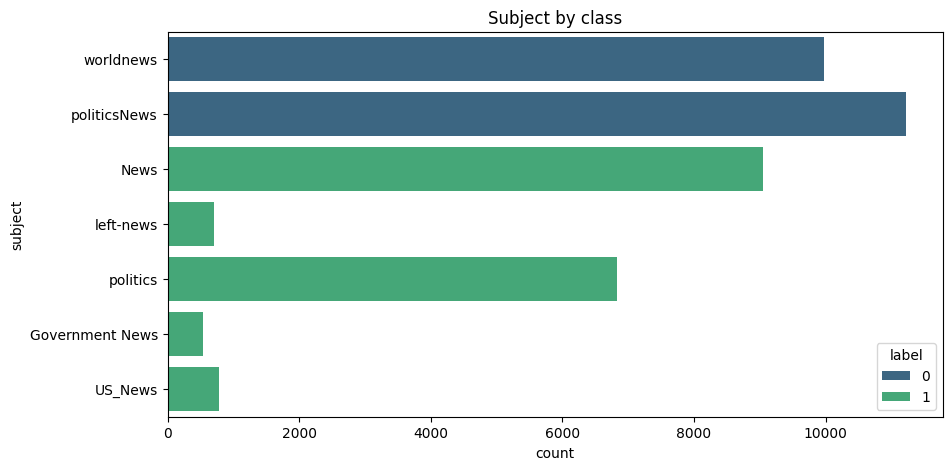

In [49]:
# subjects barely overlap between the two classes
plt.figure(figsize=(10,5))
sns.countplot(y='subject', hue='label', data=df, palette='viridis')
plt.title('Subject by class')
plt.show()

In [50]:
from wordcloud import WordCloud
from collections import Counter

In [51]:
fake_text = ' '.join(df[df['label'] == 1]['clean_text'])
real_text = ' '.join(df[df['label'] == 0]['clean_text'])

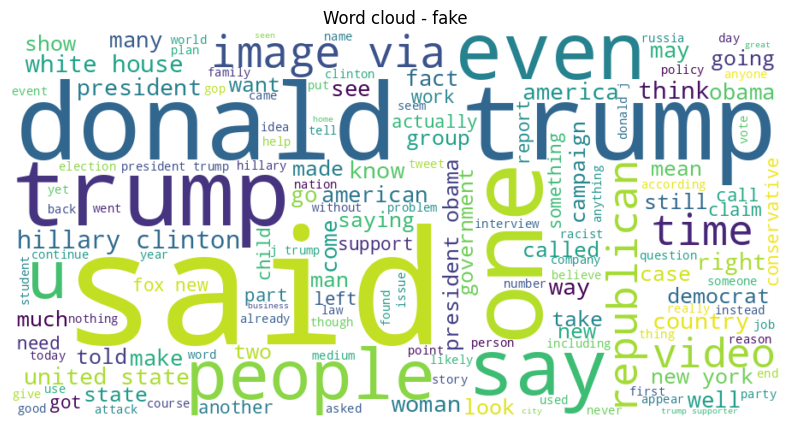

In [52]:
wc = WordCloud(width=900, height=450, background_color='white', max_words=150).generate(fake_text)
plt.figure(figsize=(10,5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud - fake')
plt.show()

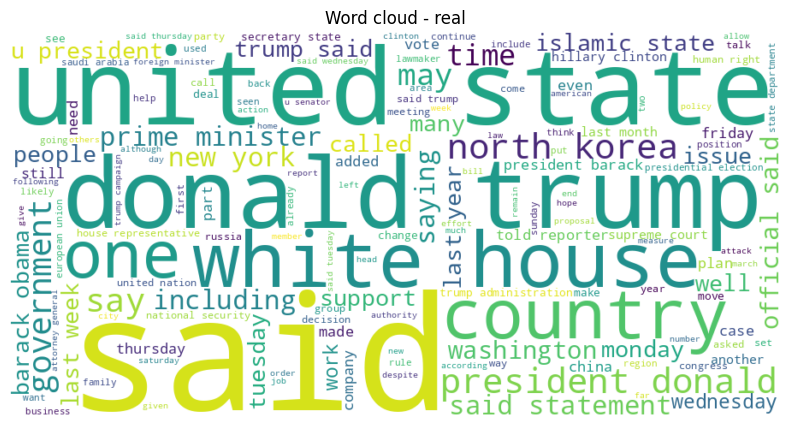

In [53]:
wc = WordCloud(width=900, height=450, background_color='white', max_words=150).generate(real_text)
plt.figure(figsize=(10,5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud - real')
plt.show()

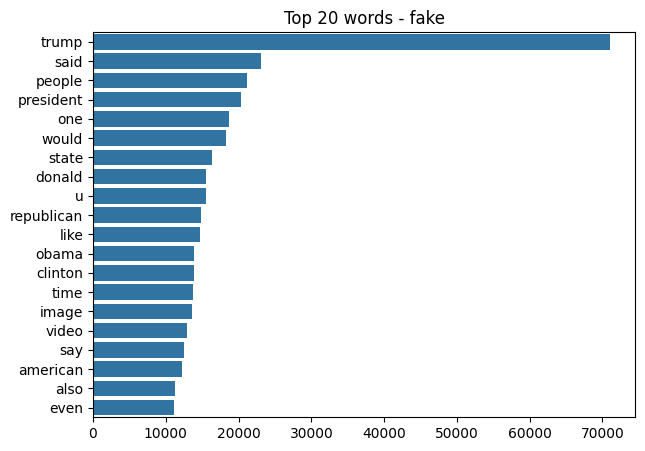

In [54]:
top_fake = Counter(fake_text.split()).most_common(20)
words, counts = zip(*top_fake)
plt.figure(figsize=(7,5))
sns.barplot(x=list(counts), y=list(words))
plt.title('Top 20 words - fake')
plt.show()

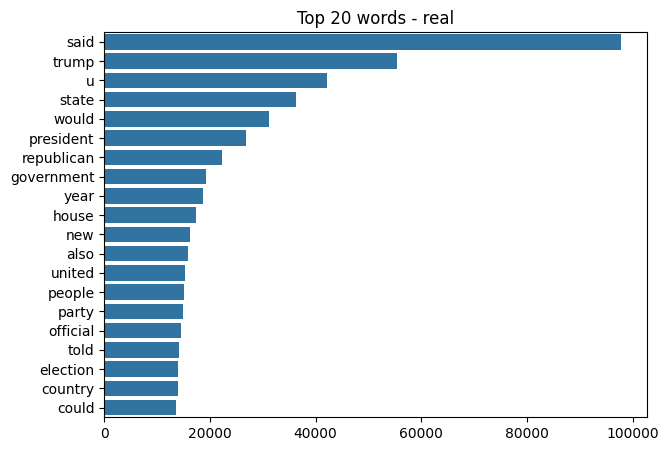

In [55]:
top_real = Counter(real_text.split()).most_common(20)
words, counts = zip(*top_real)
plt.figure(figsize=(7,5))
sns.barplot(x=list(counts), y=list(words))
plt.title('Top 20 words - real')
plt.show()

# Train Test Split

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

In [57]:
X = df['clean_text']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [58]:
X_train.shape, X_test.shape

((31271,), (7818,))

TF-IDF + Random Forest

In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=3)

In [60]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [61]:
X_train_tfidf.shape

(31271, 20000)

In [62]:
from sklearn.ensemble import RandomForestClassifier
rfc_tfidf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rfc_tfidf.fit(X_train_tfidf, y_train)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

Accuracy Score : 0.9796623177283192
              precision    recall  f1-score   support

           0    0.97135   0.99174   0.98144      4239
           1    0.98997   0.96535   0.97751      3579

    accuracy                        0.97966      7818
   macro avg    0.98066   0.97855   0.97947      7818
weighted avg    0.97987   0.97966   0.97964      7818

F1 Score : 0.97750742679304


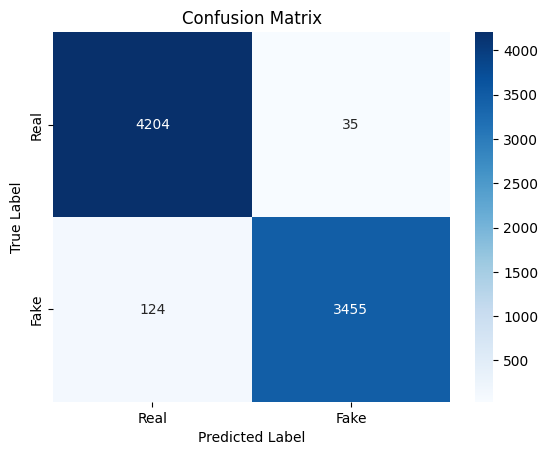

In [63]:
y_pred_tfidf = rfc_tfidf.predict(X_test_tfidf)
print('Accuracy Score :', accuracy_score(y_test, y_pred_tfidf))
cm = confusion_matrix(y_test, y_pred_tfidf)

target_names = ['Real', 'Fake']

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

print(classification_report(y_test, y_pred_tfidf, digits=5))
print('F1 Score :', f1_score(y_test, y_pred_tfidf))

Word2Vec + Random Forest

In [64]:
!pip install gensim wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 66.7 MB/s eta 0:00:00


In [65]:
from gensim.models import Word2Vec

In [66]:
# only training data is used to train word2vec
tok_train = [t.split() for t in X_train]
w2v = Word2Vec(tok_train, vector_size=100, window=5, min_count=2, workers=4, seed=42, epochs=10)

In [67]:
w2v.wv.most_similar('president')

[('presidentelect', 0.7142955660820007),
 ('presidency', 0.5750730037689209),
 ('versa', 0.546700656414032),
 ('presidential', 0.515932023525238),
 ('predecessor', 0.4940530061721802),
 ('trumpwhat', 0.48211243748664856),
 ('nomineei', 0.47886034846305847),
 ('presidentbiden', 0.47817525267601013),
 ('administration', 0.4780111610889435),
 ('trump', 0.4727833569049835)]

In [68]:
def doc_vec(text):
    vecs = []
    for w in text.split():
        if w in w2v.wv:
            vecs.append(w2v.wv[w])
    if len(vecs) == 0:
        return np.zeros(w2v.vector_size)
    return np.mean(vecs, axis = 0)

In [69]:
X_train_w2v = np.vstack([doc_vec(t) for t in X_train])
X_test_w2v = np.vstack([doc_vec(t) for t in X_test])

In [70]:
X_train_w2v.shape

(31271, 100)

In [71]:
rfc_w2v = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rfc_w2v.fit(X_train_w2v, y_train)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

Accuracy Score : 0.951394218470197
              precision    recall  f1-score   support

           0    0.94675   0.96461   0.95560      4239
           1    0.95713   0.93574   0.94631      3579

    accuracy                        0.95139      7818
   macro avg    0.95194   0.95018   0.95095      7818
weighted avg    0.95150   0.95139   0.95135      7818

F1 Score : 0.9463125176603561


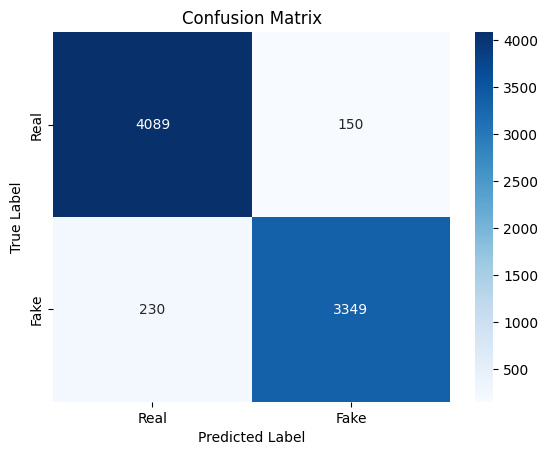

In [72]:
y_pred_w2v = rfc_w2v.predict(X_test_w2v)
print('Accuracy Score :', accuracy_score(y_test, y_pred_w2v))
cm = confusion_matrix(y_test, y_pred_w2v)

target_names = ['Real', 'Fake']

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

print(classification_report(y_test, y_pred_w2v, digits=5))
print('F1 Score :', f1_score(y_test, y_pred_w2v))

# LSTM Model

In [73]:
import tensorflow as tf
from tensorflow.keras import callbacks, layers, models
tf.keras.utils.set_random_seed(42)

In [74]:
vocab_size = 20000
max_len = 300
emb_dim = 128

In [75]:
vectorize = layers.TextVectorization(max_tokens = vocab_size, output_sequence_length = max_len)
vectorize.adapt(X_train.values)

In [76]:
def encode(series, bs = 2048):
    chunks = []
    for i in range(0, len(series), bs):
        chunks.append(vectorize(tf.constant(series.values[i:i + bs])).numpy())
    return np.vstack(chunks)

In [77]:
X_train_seq = encode(X_train)
X_test_seq = encode(X_test)

In [78]:
X_train_seq.shape

(31271, 300)

In [79]:
model = models.Sequential([
    layers.Input(shape=(max_len,)),
    layers.Embedding(vocab_size, emb_dim),
    layers.SpatialDropout1D(0.3),
    layers.LSTM(128),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

In [80]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm = 1.0), loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 300, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,700,673 (10.30 MB)

 Trainable params: 2,700,289 (10.30 MB)

 Non-trainable params: 384 (1.50 KB)

In [81]:
history = model.fit(
    X_train_seq, y_train.values,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    callbacks=[callbacks.EarlyStopping(patience=2, restore_best_weights=True)]
)

Epoch 1/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.7133 - loss: 0.5641 - val_accuracy: 0.7471 - val_loss: 0.5069
Epoch 2/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.8722 - loss: 0.3648 - val_accuracy: 0.9146 - val_loss: 0.3096
Epoch 3/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.8574 - loss: 0.3668 - val_accuracy: 0.9399 - val_loss: 0.2219
Epoch 4/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.8022 - loss: 0.4305 - val_accuracy: 0.9543 - val_loss: 0.1972
Epoch 5/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9446 - loss: 0.2016 - val_accuracy: 0.9620 - val_loss: 0.1664
Epoch 6/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.9646 - loss: 0.1327 - val_accuracy: 0.9779 - val_loss: 0.0956
Epoch 7/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9794 - loss: 0.0757 - val_accuracy: 0.9789 - val_loss: 0.1001
Epoch 8/10
440/440 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9824 - loss: 0.0622 - val_

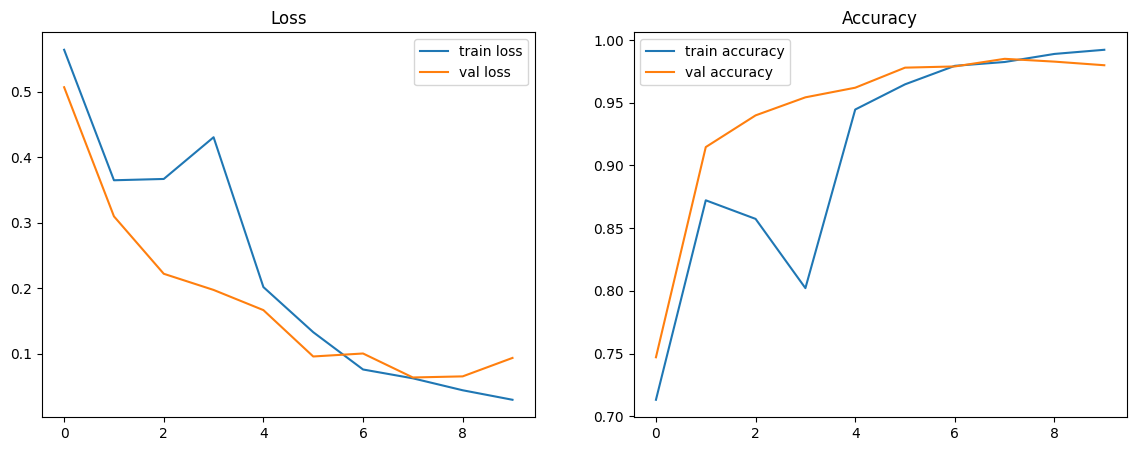

In [82]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14,5))
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_title('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train accuracy')
axes[1].plot(history.history['val_accuracy'], label='val accuracy')
axes[1].set_title('Accuracy')
axes[1].legend()
plt.show()

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
Accuracy Score : 0.9832437963673574
              precision    recall  f1-score   support

           0    0.97856   0.99080   0.98464      4239
           1    0.98894   0.97429   0.98156      3579

    accuracy                        0.98324      7818
   macro avg    0.98375   0.98255   0.98310      7818
weighted avg    0.98331   0.98324   0.98323      7818

F1 Score : 0.9815622800844476


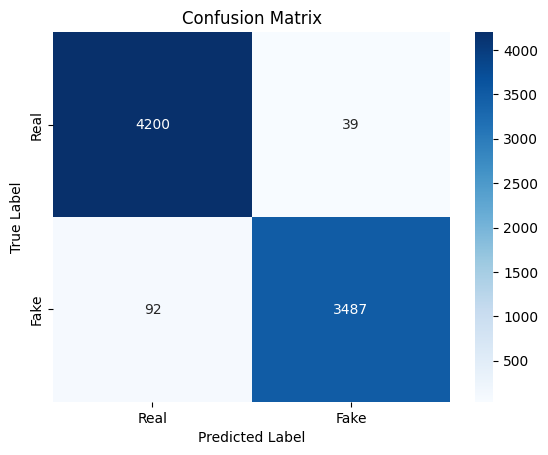

In [83]:
y_pred_lstm = (model.predict(X_test_seq, batch_size=256).ravel() > 0.5).astype(int)
print('Accuracy Score :', accuracy_score(y_test, y_pred_lstm))
cm = confusion_matrix(y_test, y_pred_lstm)

target_names = ['Real', 'Fake']

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

print(classification_report(y_test, y_pred_lstm, digits=5))
print('F1 Score :', f1_score(y_test, y_pred_lstm))

# Testing on LIAR (second dataset)

LIAR is very different from ISOT. It has short claims said by politicians (checked by PolitiFact) and not full news articles. None of the models have seen it, so this shows how well they work outside ISOT. A big drop is expected.

In [84]:
from sklearn.metrics import roc_auc_score

In [85]:
# LIAR dataset (William Wang, 2017), downloaded from the original source
# if wget fails, download liar_dataset.zip manually and upload it to /content
!wget -q https://www.cs.ucsb.edu/~william/data/liar_dataset.zip -O /content/liar_dataset.zip

import zipfile

zip_ref = zipfile.ZipFile('/content/liar_dataset.zip', 'r')
zip_ref.extractall('/content/liar')
zip_ref.close()

In [86]:
!ls /content/liar

README	test.tsv  train.tsv  valid.tsv


In [87]:
cols = ['id', 'label', 'statement', 'subject', 'speaker', 'job_title', 'state', 'party',
        'barely_true_count', 'false_count', 'half_true_count', 'mostly_true_count', 'pants_fire_count', 'context']

liar_train = pd.read_csv('/content/liar/train.tsv', sep='\t', header=None, names=cols, quoting=3)
liar_valid = pd.read_csv('/content/liar/valid.tsv', sep='\t', header=None, names=cols, quoting=3)
liar_test = pd.read_csv('/content/liar/test.tsv', sep='\t', header=None, names=cols, quoting=3)

In [88]:
# none of the models are trained on LIAR so all the three files can be used for testing
liar = pd.concat([liar_train, liar_valid, liar_test], ignore_index = True)

In [89]:
liar.shape

(12836, 14)

In [90]:
liar.head()

,id,label,statement,subject,speaker,job_title,state,party,barely_true_count,false_count,half_true_count,mostly_true_count,pants_fire_count,context
0,2635.json,false,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0,1,0,0,0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0,0,1,1,0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by vo...",foreign-policy,barack-obama,President,Illinois,democrat,70,71,160,163,9,Denver
3,1123.json,false,Health care reform legislation is likely to ma...,health-care,blog-posting,NaN,NaN,none,7,19,3,5,44,a news release
4,9028.json,half-true,The economic turnaround started at the end of ...,"economy,jobs",charlie-crist,NaN,Florida,democrat,15,9,20,19,2,an interview on CNN


In [91]:
liar.isnull().sum()

,0
id,0
label,0
statement,0
subject,0
speaker,0
job_title,3576
state,2754
party,0
barely_true_count,0
false_count,0


In [92]:
liar['label'].value_counts()

,count
label,
half-true,2638
false,2511
mostly-true,2466
barely-true,2108
true,2063
pants-fire,1050


In [93]:
# pants-fire, false and barely-true -> fake (1), half-true, mostly-true and true -> real (0)
fake_labels = ['pants-fire', 'false', 'barely-true']
liar['fake'] = liar['label'].apply(lambda x: 1 if x in fake_labels else 0)
y_liar = liar['fake']

In [94]:
liar['fake'].value_counts()

,count
fake,
0,7167
1,5669


In [95]:
# accuracy of a model that says the same class for everything
print('Majority class accuracy :', y_liar.value_counts(normalize = True).max())

Majority class accuracy : 0.5583515113742599


In [96]:
liar['n_words'] = liar['statement'].fillna('').str.split().str.len()
liar['n_words'].describe()

,n_words
count,12836.000000
mean,17.914693
std,7.748308
min,2.000000
25%,12.000000
50%,17.000000
75%,22.000000
max,66.000000


In [97]:
df['n_words'].describe()

,n_words
count,39089.000000
mean,229.385351
std,177.765559
min,6.000000
25%,124.000000
50%,209.000000
75%,288.000000
max,4830.000000


In [98]:
# same cleaning as ISOT, for the tfidf / word2vec / lstm models
liar['clean_text'] = liar['statement'].fillna('').apply(preprocess)

In [99]:
liar[['statement', 'clean_text', 'fake']].head()

,statement,clean_text,fake
0,Says the Annies List political group supports ...,say annies list political group support thirdt...,1
1,When did the decline of coal start? It started...,decline coal start started natural gas took st...,0
2,"Hillary Clinton agrees with John McCain ""by vo...",hillary clinton agrees john mccain voting give...,0
3,Health care reform legislation is likely to ma...,health care reform legislation likely mandate ...,1
4,The economic turnaround started at the end of ...,economic turnaround started end term,0


TF-IDF + Random Forest on LIAR

In [100]:
y_prob_liar_tfidf = rfc_tfidf.predict_proba(tfidf.transform(liar['clean_text']))[:, 1]
y_pred_liar_tfidf = (y_prob_liar_tfidf > 0.5).astype(int)

print('Accuracy Score :', accuracy_score(y_liar, y_pred_liar_tfidf))
print(classification_report(y_liar, y_pred_liar_tfidf, digits=5))
print('F1 Score :', f1_score(y_liar, y_pred_liar_tfidf))
print('AUC :', roc_auc_score(y_liar, y_prob_liar_tfidf))

Accuracy Score : 0.4535680897475849
              precision    recall  f1-score   support

           0    0.58644   0.07242   0.12891      7167
           1    0.44373   0.93544   0.60193      5669

    accuracy                        0.45357     12836
   macro avg    0.51508   0.50393   0.36542     12836
weighted avg    0.52341   0.45357   0.33782     12836

F1 Score : 0.6019296254256526
AUC : 0.5348796741735109


Word2Vec + Random Forest on LIAR

In [101]:
X_liar_w2v = np.vstack([doc_vec(t) for t in liar['clean_text']])
y_prob_liar_w2v = rfc_w2v.predict_proba(X_liar_w2v)[:, 1]
y_pred_liar_w2v = (y_prob_liar_w2v > 0.5).astype(int)

print('Accuracy Score :', accuracy_score(y_liar, y_pred_liar_w2v))
print(classification_report(y_liar, y_pred_liar_w2v, digits=5))
print('F1 Score :', f1_score(y_liar, y_pred_liar_w2v))
print('AUC :', roc_auc_score(y_liar, y_prob_liar_w2v))

Accuracy Score : 0.5200218136491118
              precision    recall  f1-score   support

           0    0.59243   0.44984   0.51138      7167
           1    0.46673   0.60875   0.52836      5669

    accuracy                        0.52002     12836
   macro avg    0.52958   0.52929   0.51987     12836
weighted avg    0.53691   0.52002   0.51888     12836

F1 Score : 0.5283625507157621
AUC : 0.5412539731073235


LSTM on LIAR

In [102]:
X_liar_seq = encode(liar['clean_text'])
y_prob_liar_lstm = model.predict(X_liar_seq, batch_size=256).ravel()
y_pred_liar_lstm = (y_prob_liar_lstm > 0.5).astype(int)

print('Accuracy Score :', accuracy_score(y_liar, y_pred_liar_lstm))
print(classification_report(y_liar, y_pred_liar_lstm, digits=5))
print('F1 Score :', f1_score(y_liar, y_pred_liar_lstm))
print('AUC :', roc_auc_score(y_liar, y_prob_liar_lstm))

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
Accuracy Score : 0.5166718603926457
              precision    recall  f1-score   support

           0    0.58083   0.48277   0.52728      7167
           1    0.46111   0.55953   0.50558      5669

    accuracy                        0.51667     12836
   macro avg    0.52097   0.52115   0.51643     12836
weighted avg    0.52796   0.51667   0.51769     12836

F1 Score : 0.5055785782594836
AUC : 0.5250106430703453


In [103]:
# lstm weights, the random forests are not saved because they are big and their predictions are already saved below
model.save(save_dir + '/lstm_model.keras')

In [104]:
liar[['statement', 'fake']].to_csv(save_dir + '/liar_clean.csv', index = False)

np.savez(save_dir + '/part1_results.npz',
         y_test = y_test.values,
         y_pred_tfidf = y_pred_tfidf, y_pred_w2v = y_pred_w2v, y_pred_lstm = y_pred_lstm,
         y_liar = y_liar.values,
         y_prob_liar_tfidf = y_prob_liar_tfidf, y_prob_liar_w2v = y_prob_liar_w2v, y_prob_liar_lstm = y_prob_liar_lstm,
         y_pred_liar_tfidf = y_pred_liar_tfidf, y_pred_liar_w2v = y_pred_liar_w2v, y_pred_liar_lstm = y_pred_liar_lstm)
print('saved')

saved


Part 1 is done, the files are in your Drive folder `fake_news_classifier`. Now open `FakeNewsClassification_Part2_DistilBERT.ipynb` in a new session.